# T0101 — EDA dữ liệu Beijing Multi-Site Air Quality

Notebook khám phá dữ liệu gốc của 12 trạm quan trắc trước khi tiền xử lý.

**Thư mục dữ liệu:** `data/raw/PRSA2017/`  
**Đầu ra EDA:** `outputs/eda/`

Thứ tự thực hiện: nạp dữ liệu → xem 5 dòng đầu → cấu trúc và thống kê mô tả → kiểm tra chất lượng → phân tích missing values → phân phối và ngoại lệ → tương quan → phân tích thời gian → kiểm tra từng trạm.

In [38]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
DATA_DIR = Path("../data/raw/PRSA2017")
OUT_DIR = Path("../outputs/eda")
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "pm2.5"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## 1. Nạp dữ liệu 12 trạm

In [20]:
# Tìm thư mục gốc project, không phụ thuộc đường dẫn máy tính
current = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path for path in (current, *current.parents)
        if (path / "data" / "raw").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục gốc project.")

# Đường dẫn thư mục dữ liệu
DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "PRSA_Data_20130301-20170228"
)

# Đọc dữ liệu CSV
csv_files = sorted(DATA_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"Không tìm thấy file CSV trong: {DATA_DIR.resolve()}"
    )

frames = []

for file in csv_files:
    station_df = pd.read_csv(file)
    station_df.columns = station_df.columns.str.strip().str.lower()

    if "station" not in station_df.columns:
        station_df["station"] = file.stem.replace("PRSA_Data_", "")

    frames.append(station_df)

df = pd.concat(frames, ignore_index=True)

print(f"Số file/trạm: {len(csv_files)}")
print(f"Kích thước dữ liệu: {df.shape}")
display(df.head())


Số file/trạm: 12
Kích thước dữ liệu: (420768, 18)


,no,year,month,day,hour,pm2.5,pm10,so2,no2,co,o3,temp,pres,dewp,rain,wd,wspm,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


## 2. Quan sát 5 dòng đầu và cuối

In [21]:
display(df.head(5))
display(df.tail(5))

,no,year,month,day,hour,pm2.5,pm10,so2,no2,co,o3,temp,pres,dewp,rain,wd,wspm,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


,no,year,month,day,hour,pm2.5,pm10,so2,no2,co,o3,temp,pres,dewp,rain,wd,wspm,station
420763,35060,2017,2,28,19,11.0,32.0,3.0,24.0,400.0,72.0,12.5,1013.5,-16.2,0.0,NW,2.4,Wanshouxigong
420764,35061,2017,2,28,20,13.0,32.0,3.0,41.0,500.0,50.0,11.6,1013.6,-15.1,0.0,WNW,0.9,Wanshouxigong
420765,35062,2017,2,28,21,14.0,28.0,4.0,38.0,500.0,54.0,10.8,1014.2,-13.3,0.0,NW,1.1,Wanshouxigong
420766,35063,2017,2,28,22,12.0,23.0,4.0,30.0,400.0,59.0,10.5,1014.4,-12.9,0.0,NNW,1.2,Wanshouxigong
420767,35064,2017,2,28,23,13.0,19.0,4.0,38.0,600.0,49.0,8.6,1014.1,-15.9,0.0,NNE,1.3,Wanshouxigong


## 3. Cấu trúc dữ liệu và kiểu dữ liệu

In [22]:
df.info()
print("\nTên các cột:")
print(df.columns.tolist())

print("\nKiểu dữ liệu:")
display(df.dtypes.to_frame("data_type"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   no       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   pm2.5    412029 non-null  float64
 6   pm10     414319 non-null  float64
 7   so2      411747 non-null  float64
 8   no2      408652 non-null  float64
 9   co       400067 non-null  float64
 10  o3       407491 non-null  float64
 11  temp     420370 non-null  float64
 12  pres     420375 non-null  float64
 13  dewp     420365 non-null  float64
 14  rain     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  wspm     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB

Tên các cột:
['no', 'year', 'month', 'day', 

,data_type
no,int64
year,int64
month,int64
day,int64
hour,int64
pm2.5,float64
pm10,float64
so2,float64
no2,float64
co,float64


## 4. Thống kê mô tả — describe()

In [23]:
print("Thống kê các biến số:")
display(df.describe())

print("Thống kê tất cả biến, gồm cả biến phân loại:")
display(df.describe(include="all").T)

Thống kê các biến số:


,no,year,month,day,hour,pm2.5,pm10,so2,no2,co,o3,temp,pres,dewp,rain,wspm
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,420450.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,1.729711
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,1.246386
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


Thống kê tất cả biến, gồm cả biến phân loại:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
no,420768.0,NaN,NaN,NaN,17532.5,10122.116943,1.0,8766.75,17532.5,26298.25,35064.0
year,420768.0,NaN,NaN,NaN,2014.66256,1.177198,2013.0,2014.0,2015.0,2016.0,2017.0
month,420768.0,NaN,NaN,NaN,6.52293,3.448707,1.0,4.0,7.0,10.0,12.0
day,420768.0,NaN,NaN,NaN,15.729637,8.800102,1.0,8.0,16.0,23.0,31.0
hour,420768.0,NaN,NaN,NaN,11.5,6.922195,0.0,5.75,11.5,17.25,23.0
pm2.5,412029.0,NaN,NaN,NaN,79.793428,80.822391,2.0,20.0,55.0,111.0,999.0
pm10,414319.0,NaN,NaN,NaN,104.602618,91.772426,2.0,36.0,82.0,145.0,999.0
so2,411747.0,NaN,NaN,NaN,15.830835,21.650603,0.2856,3.0,7.0,20.0,500.0
no2,408652.0,NaN,NaN,NaN,50.638586,35.127912,1.0265,23.0,43.0,71.0,290.0
co,400067.0,NaN,NaN,NaN,1230.766454,1160.182716,100.0,500.0,900.0,1500.0,10000.0


## 5. Kiểm tra chất lượng dữ liệu

In [24]:
print("Kích thước:", df.shape)
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())
print("Số giá trị duy nhất theo cột:")
display(df.nunique(dropna=False).to_frame("unique_values"))

if {"year", "month", "day", "hour"}.issubset(df.columns):
    df["datetime"] = pd.to_datetime(
        df[["year", "month", "day", "hour"]], errors="coerce"
    )
    print("Thời gian không hợp lệ:", df["datetime"].isna().sum())
    print("Thời điểm sớm nhất:", df["datetime"].min())
    print("Thời điểm muộn nhất:", df["datetime"].max())

Kích thước: (420768, 18)
Số dòng trùng hoàn toàn: 0
Số giá trị duy nhất theo cột:


,unique_values
no,35064
year,5
month,12
day,31
hour,24
pm2.5,889
pm10,1085
so2,692
no2,1213
co,133


Thời gian không hợp lệ: 0
Thời điểm sớm nhất: 2013-03-01 00:00:00
Thời điểm muộn nhất: 2017-02-28 23:00:00


## 6. Phân tích Missing Values

,missing_count,missing_rate
co,20701,4.919813
o3,13277,3.155421
no2,12116,2.879497
so2,9021,2.143937
pm2.5,8739,2.076916
pm10,6449,1.532674
wd,1822,0.433018
dewp,403,0.095777
temp,398,0.094589
pres,393,0.093401


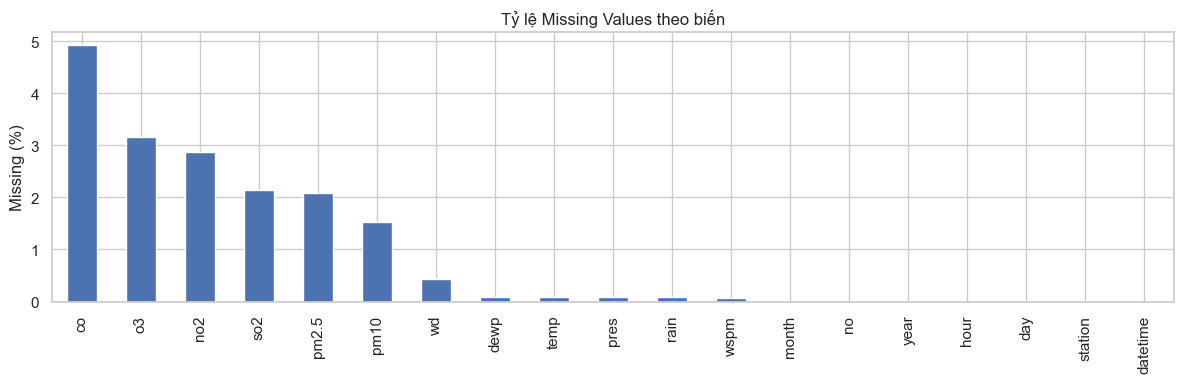

In [25]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_rate": df.isna().mean() * 100
}).sort_values("missing_rate", ascending=False)

display(missing)
missing.to_csv(OUT_DIR / "missing_overall.csv")

ax = missing["missing_rate"].plot(kind="bar", figsize=(12, 4))
ax.set_title("Tỷ lệ Missing Values theo biến")
ax.set_ylabel("Missing (%)")
plt.tight_layout()
plt.savefig(OUT_DIR / "missing_by_column.png", dpi=150)
plt.show()

In [26]:
if "station" in df.columns:
    missing_station = df.groupby("station").apply(
        lambda x: x.isna().mean() * 100,
        include_groups=False
    )
    display(missing_station)
    missing_station.to_csv(OUT_DIR / "missing_by_station.csv")

if "datetime" in df.columns:
    missing_month = (
        df.set_index("datetime")
          .groupby("station")
          .resample("MS")
          .mean(numeric_only=True)
    )
    display(missing_month.head())

,no,year,month,day,hour,pm2.5,pm10,so2,no2,co,o3,temp,pres,dewp,rain,wd,wspm,datetime
station,,,,,,,,,,,,,,,,,,
Aotizhongxin,0.0,0.0,0.0,0.0,0.0,2.638033,2.047684,2.666553,2.917522,5.065024,4.902464,0.057039,0.057039,0.057039,0.057039,0.231006,0.039927,0.0
Changping,0.0,0.0,0.0,0.0,0.0,2.207392,1.659822,1.791011,1.902236,4.337782,1.722564,0.151152,0.142596,0.151152,0.145448,0.399270,0.122633,0.0
Dingling,0.0,0.0,0.0,0.0,0.0,2.221652,1.870865,2.081907,3.519279,5.738079,3.462240,0.151152,0.142596,0.151152,0.145448,0.399270,0.122633,0.0
Dongsi,0.0,0.0,0.0,0.0,0.0,2.138946,1.577116,1.890828,4.565937,9.117614,1.893680,0.057039,0.057039,0.057039,0.057039,0.222450,0.039927,0.0
Guanyuan,0.0,0.0,0.0,0.0,0.0,1.756788,1.223477,1.351814,1.879420,4.999430,3.345311,0.057039,0.057039,0.057039,0.057039,0.231006,0.039927,0.0
Gucheng,0.0,0.0,0.0,0.0,0.0,1.842345,1.086585,1.445927,1.905088,3.995551,2.079055,0.145448,0.142596,0.145448,0.122633,0.453457,0.119781,0.0
Huairou,0.0,0.0,0.0,0.0,0.0,2.717887,2.215948,2.794889,4.674310,4.055441,3.282569,0.145448,0.151152,0.151152,0.156856,0.861282,0.139744,0.0
Nongzhanguan,0.0,0.0,0.0,0.0,0.0,1.791011,1.254848,1.271960,1.973534,3.439425,1.443076,0.057039,0.057039,0.057039,0.057039,0.222450,0.039927,0.0
Shunyi,0.0,0.0,0.0,0.0,0.0,2.603810,1.562856,3.696099,3.892882,6.211499,4.246521,0.145448,0.145448,0.154004,0.145448,1.377481,0.125485,0.0


C:\Users\dvt\AppData\Local\Temp\ipykernel_6260\2511262891.py:14: FutureWarning: DataFrameGroupBy.resample operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .mean(numeric_only=True)


no    year  month   day  hour       pm2.5        pm10        so2        no2           co  \
station      datetime                                                                                                   
Aotizhongxin 2013-03-01   372.5  2013.0    3.0  16.0  11.5  110.092742  144.000000  45.064803  74.779855  1493.201807   
             2013-04-01  1104.5  2013.0    4.0  15.5  11.5   62.751389  108.204167  24.725745  53.269269   915.426918   
             2013-05-01  1836.5  2013.0    5.0  16.0  11.5   84.987871  140.778226  30.442204  61.016129   932.773556   
             2013-06-01  2568.5  2013.0    6.0  15.5  11.5  106.225941  128.716667  14.637068  72.888399  1345.887352   
             2013-07-01  3300.5  2013.0    7.0  16.0  11.5   68.911290   85.370620   9.292740  55.131272   815.471591   

                                o3       temp         pres       dewp      rain      wspm  
station      datetime                                                                      
Aotizhongxin 2013-03-01  47.489290   6.053629  1012.547446  -5.729435  0.026210  2.000134  
             2013-04-01  50.123976  12.260694  1008.296944  -1.553611  0.015139  2.209722  
             2013-05-01  75.413386  21.374194  1003.162231   9.790457  0.007796  1.740457  
             2013-06-01  71.125876  23.386111  1000.165556  18.009028  0.130694  1.240000  
             2013-07-01  72.471187  26.877419   996.033065  21.459946  0.293817  1.278763

## 7. Phân phối biến và phát hiện ngoại lệ

array([[<Axes: title={'center': 'no'}>, <Axes: title={'center': 'year'}>,
        <Axes: title={'center': 'month'}>,
        <Axes: title={'center': 'day'}>],
       [<Axes: title={'center': 'hour'}>,
        <Axes: title={'center': 'pm2.5'}>,
        <Axes: title={'center': 'pm10'}>,
        <Axes: title={'center': 'so2'}>],
       [<Axes: title={'center': 'no2'}>, <Axes: title={'center': 'co'}>,
        <Axes: title={'center': 'o3'}>, <Axes: title={'center': 'temp'}>],
       [<Axes: title={'center': 'pres'}>,
        <Axes: title={'center': 'dewp'}>,
        <Axes: title={'center': 'rain'}>,
        <Axes: title={'center': 'wspm'}>]], dtype=object)

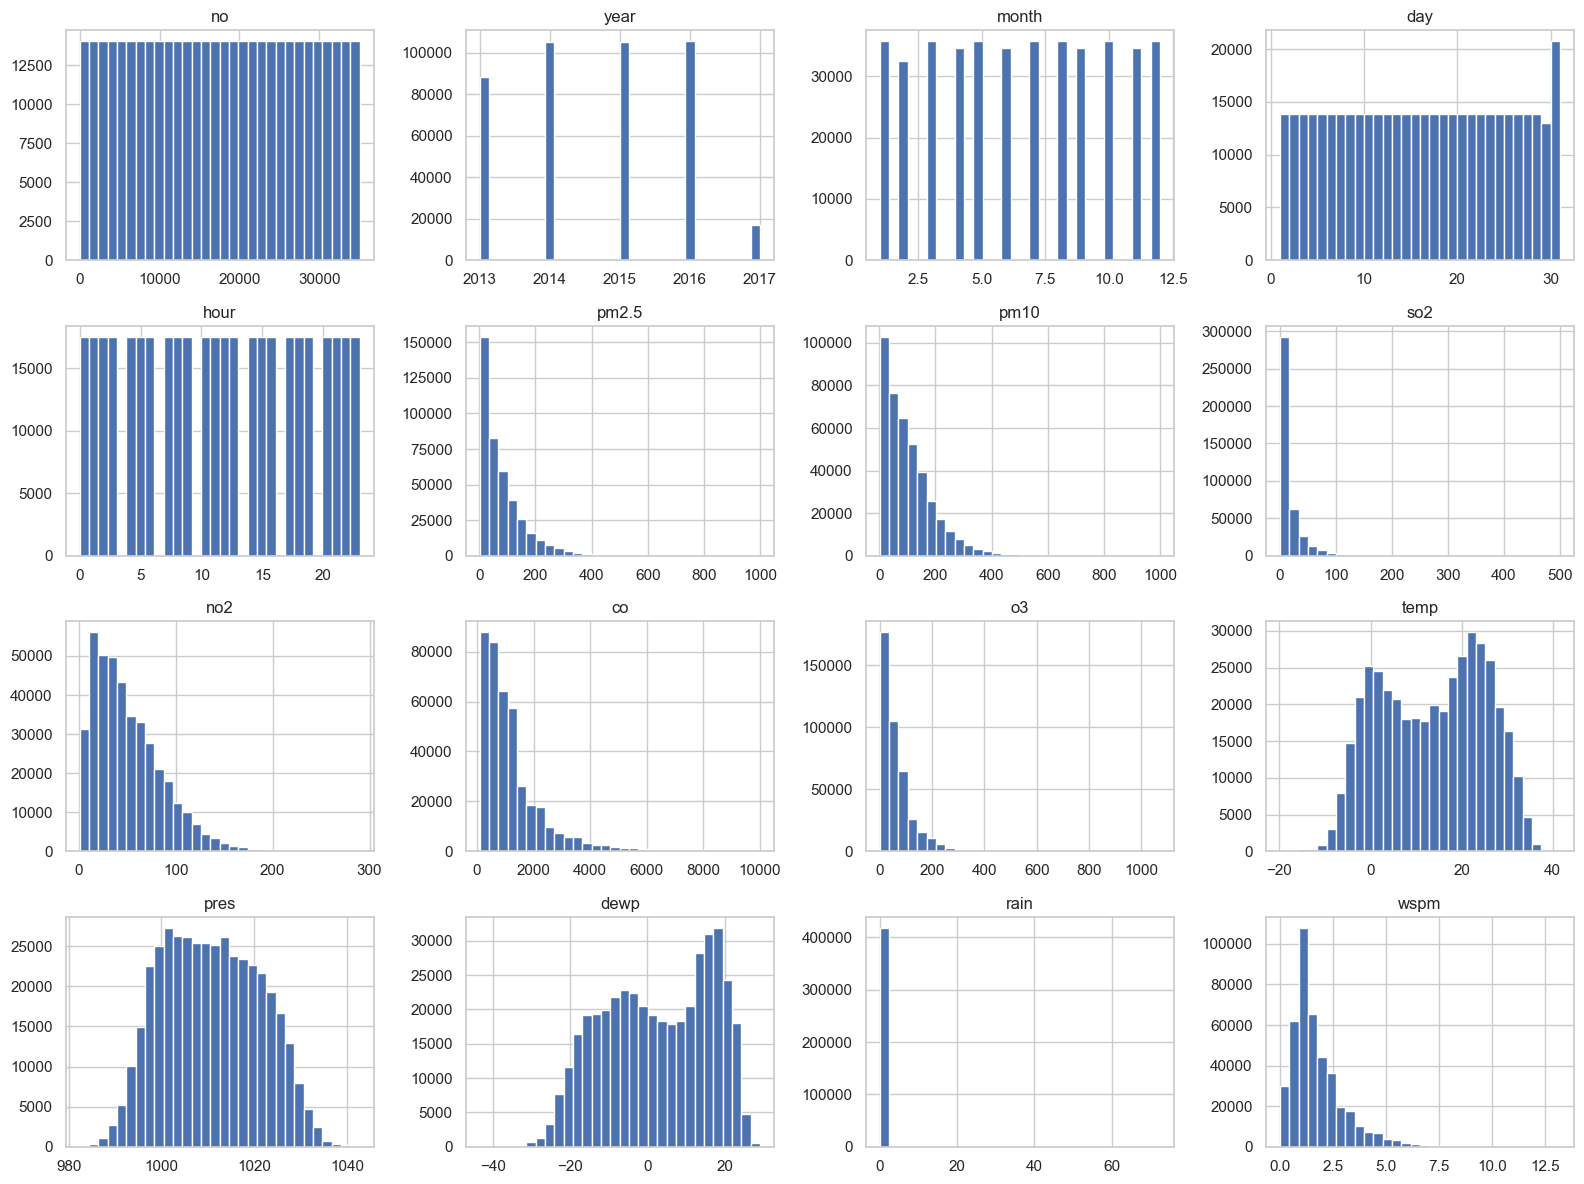

In [27]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].hist(figsize=(16, 12), bins=30))
plt.tight_layout()
plt.savefig(OUT_DIR / "numeric_distributions.png", dpi=150)
plt.show()

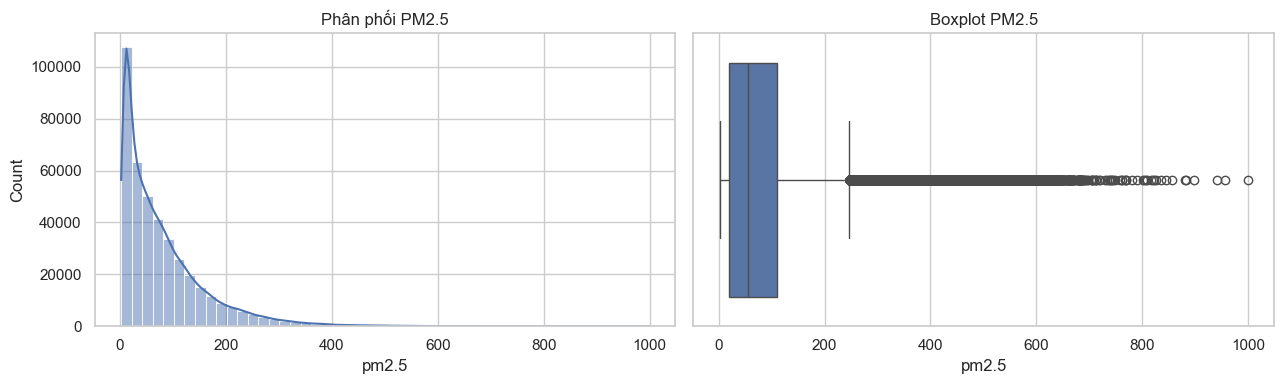

In [28]:
if TARGET in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    sns.histplot(df[TARGET].dropna(), bins=50, kde=True, ax=axes[0])
    axes[0].set_title("Phân phối PM2.5")
    sns.boxplot(x=df[TARGET], ax=axes[1])
    axes[1].set_title("Boxplot PM2.5")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "pm25_distribution_outliers.png", dpi=150)
    plt.show()

## 8. Kiểm tra mất cân bằng lớp (nếu chuyển thành bài toán phân loại)

PM2.5 nguyên bản là biến liên tục nên đây là bài toán hồi quy, không có class imbalance trực tiếp. Chỉ sử dụng phần dưới nếu nhóm định nghĩa nhãn phân loại và thống nhất ngưỡng với đề tài.

pm25_class_demo
high      0.382638
low       0.365691
medium    0.230902
NaN       0.020769
Name: class_ratio, dtype: float64

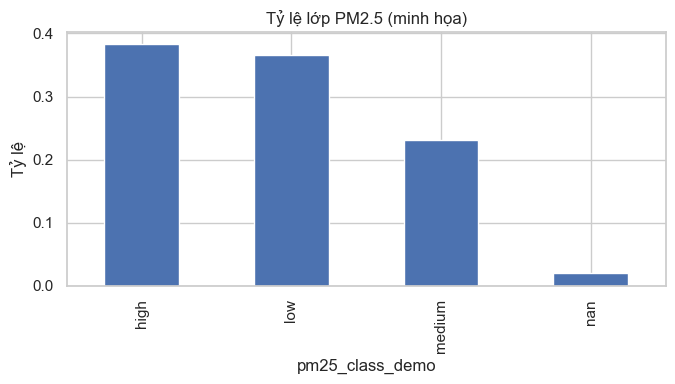

In [29]:
if TARGET in df.columns:
    # Ngưỡng minh họa; cần thay bằng ngưỡng đã thống nhất trong đề tài.
    bins = [-np.inf, 35, 75, np.inf]
    labels = ["low", "medium", "high"]
    df["pm25_class_demo"] = pd.cut(df[TARGET], bins=bins, labels=labels)
    class_ratio = df["pm25_class_demo"].value_counts(normalize=True, dropna=False)
    display(class_ratio.rename("class_ratio"))
    class_ratio.plot(kind="bar", figsize=(7, 4), title="Tỷ lệ lớp PM2.5 (minh họa)")
    plt.ylabel("Tỷ lệ")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "class_imbalance_demo.png", dpi=150)
    plt.show()

## 9. Phân tích tương quan giữa các biến số

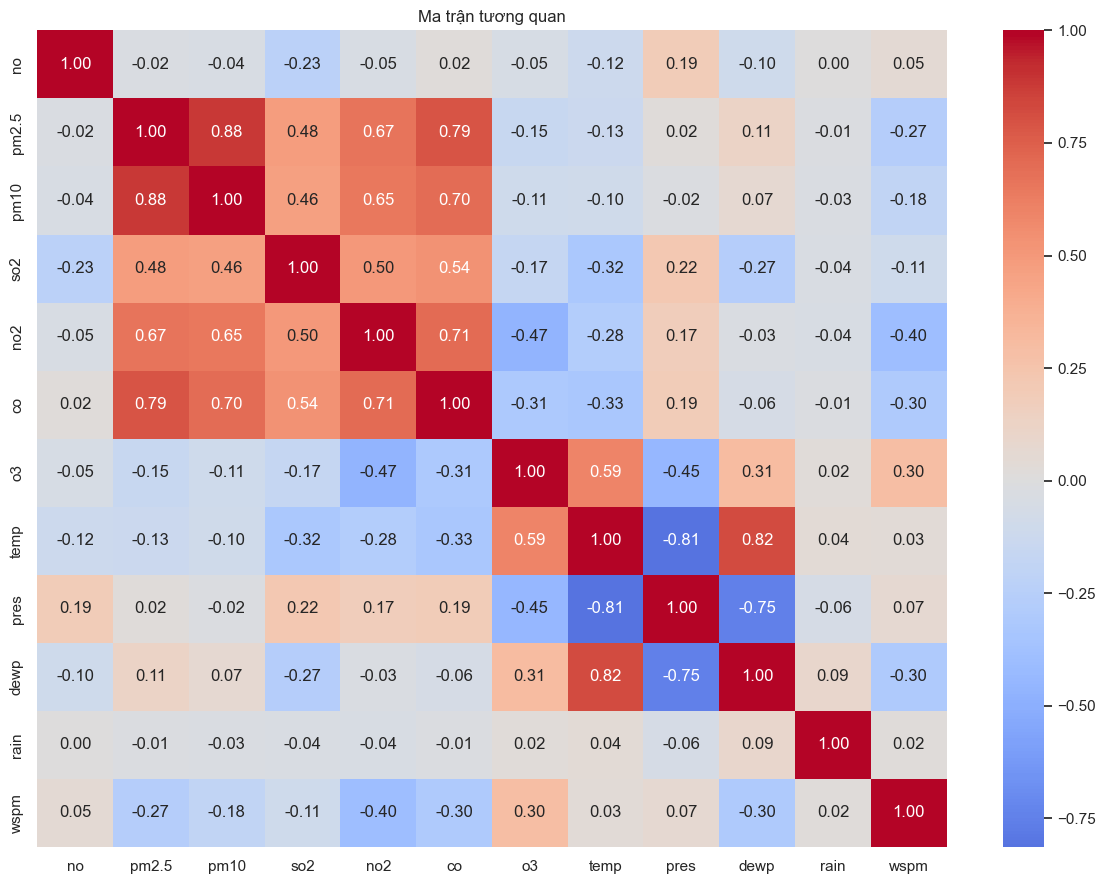

,correlation_with_pm25
pm2.5,1.000000
pm10,0.884380
co,0.789998
no2,0.666948
so2,0.482354
dewp,0.114656
pres,0.018566
rain,-0.014359
no,-0.023569
temp,-0.131127


In [30]:
corr_cols = [c for c in numeric_cols if c not in ["year", "month", "day", "hour"]]
if len(corr_cols) >= 2:
    corr = df[corr_cols].corr()
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
    plt.title("Ma trận tương quan")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "correlation_heatmap.png", dpi=150)
    plt.show()

    if TARGET in corr.columns:
        display(corr[TARGET].sort_values(ascending=False).to_frame("correlation_with_pm25"))

## 10. Phân tích chu kỳ thời gian

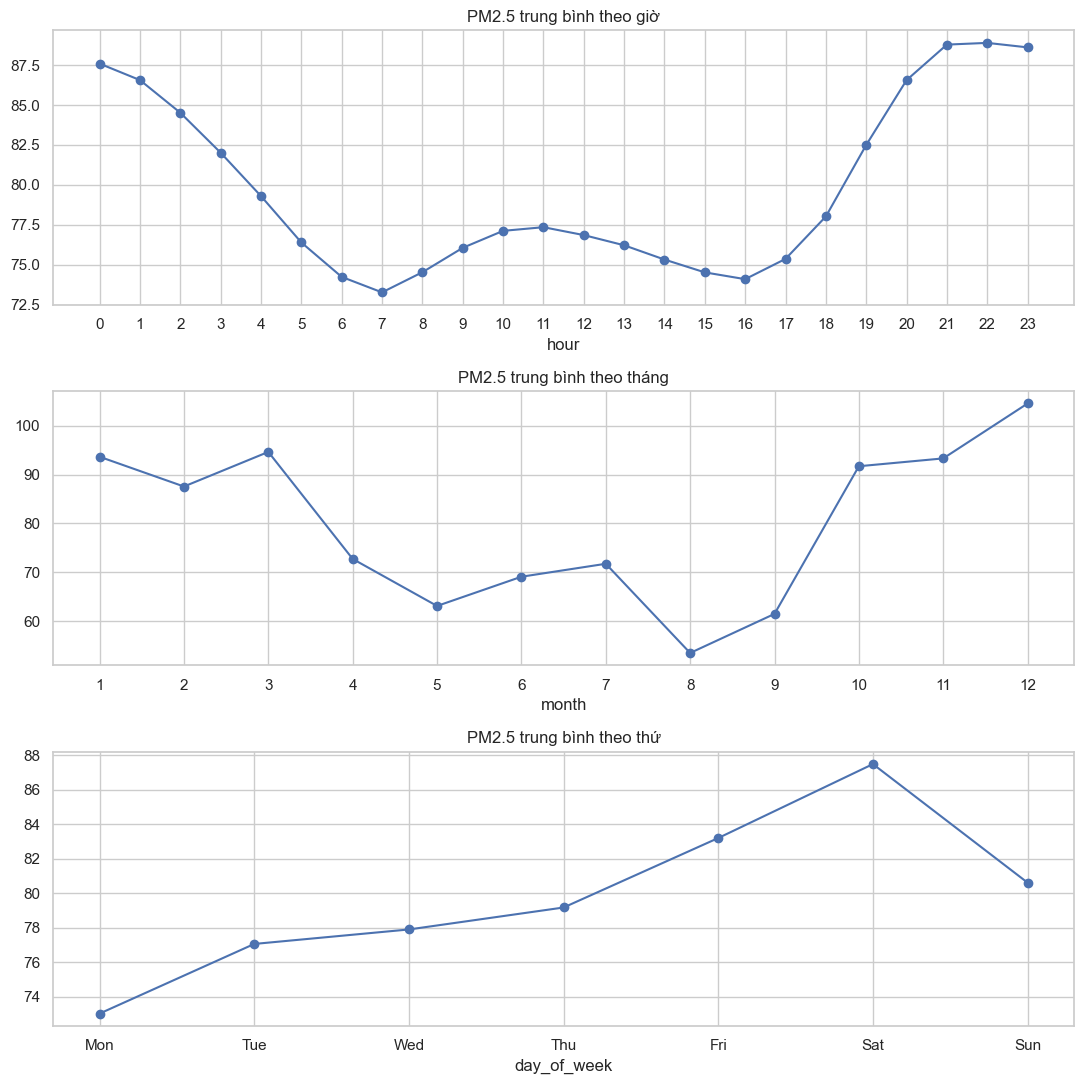

In [31]:
if "datetime" in df.columns and TARGET in df.columns:
    time_df = df.dropna(subset=["datetime"]).copy()
    time_df["hour"] = time_df["datetime"].dt.hour
    time_df["month"] = time_df["datetime"].dt.month
    time_df["day_of_week"] = time_df["datetime"].dt.dayofweek

    hourly = time_df.groupby("hour")[TARGET].mean()
    monthly = time_df.groupby("month")[TARGET].mean()
    weekday = time_df.groupby("day_of_week")[TARGET].mean()

    fig, axes = plt.subplots(3, 1, figsize=(11, 11))
    hourly.plot(marker="o", ax=axes[0], title="PM2.5 trung bình theo giờ")
    monthly.plot(marker="o", ax=axes[1], title="PM2.5 trung bình theo tháng")
    weekday.plot(marker="o", ax=axes[2], title="PM2.5 trung bình theo thứ")
    axes[0].set_xticks(range(24))
    axes[1].set_xticks(range(1, 13))
    axes[2].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
    plt.tight_layout()
    plt.savefig(OUT_DIR / "temporal_patterns.png", dpi=150)
    plt.show()

## 11. Xu hướng PM2.5 theo thời gian và theo trạm

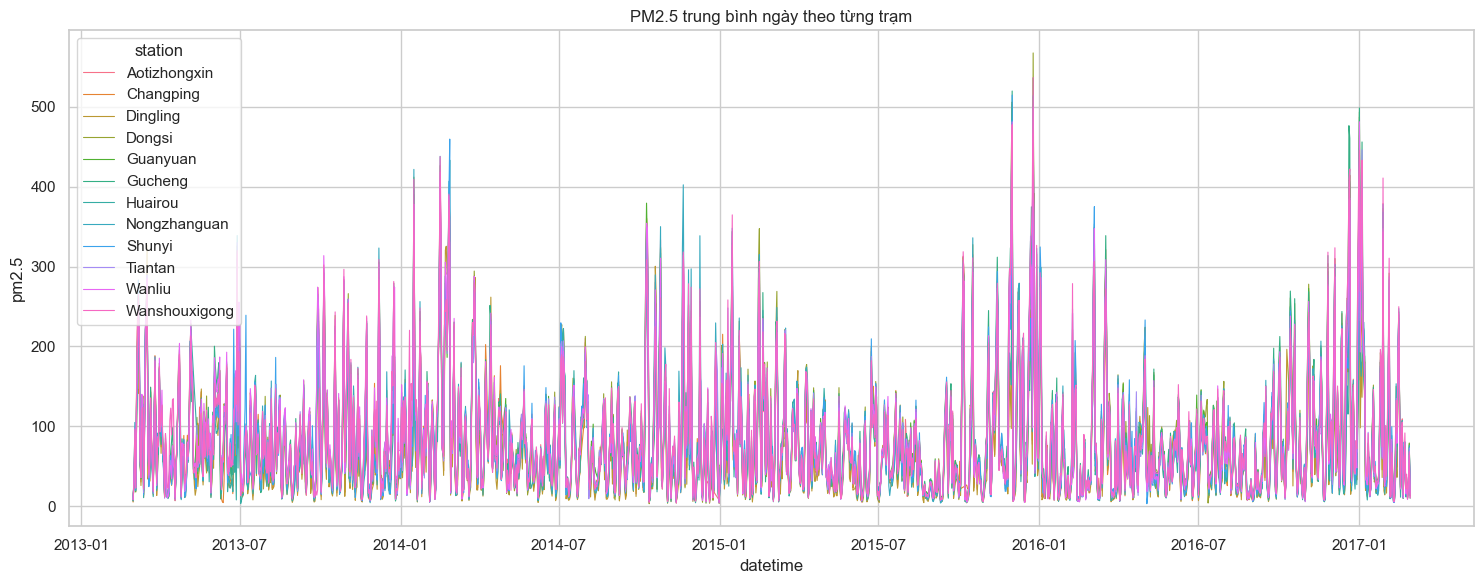

In [32]:
if {"datetime", TARGET, "station"}.issubset(df.columns):
    daily = (
        df.dropna(subset=["datetime"])
          .set_index("datetime")
          .groupby("station")[TARGET]
          .resample("D")
          .mean()
          .reset_index()
    )
    plt.figure(figsize=(15, 6))
    sns.lineplot(data=daily, x="datetime", y=TARGET, hue="station", linewidth=0.8)
    plt.title("PM2.5 trung bình ngày theo từng trạm")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "pm25_daily_by_station.png", dpi=150)
    plt.show()

## 12. Kiểm tra hướng gió và các biến khí tượng

,count
wd,
NE,43335
ENE,34142
NW,32600
N,30869
E,29752
SW,28756
NNE,28232
NNW,25326
WNW,24375


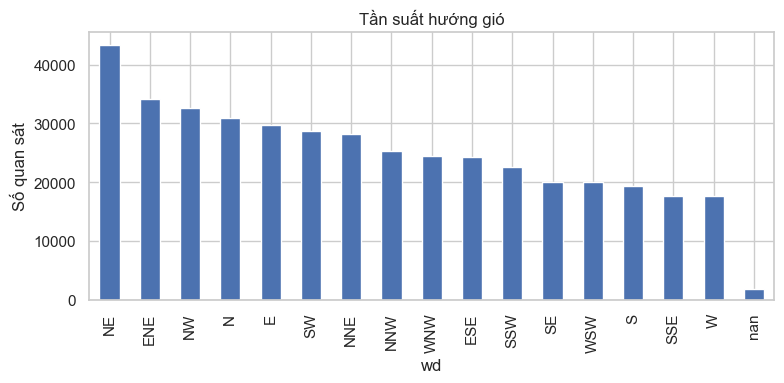

In [33]:
if "wd" in df.columns:
    wind_counts = df["wd"].value_counts(dropna=False)
    display(wind_counts.to_frame("count"))
    wind_counts.plot(kind="bar", figsize=(8, 4), title="Tần suất hướng gió")
    plt.ylabel("Số quan sát")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "wind_direction_counts.png", dpi=150)
    plt.show()

## 13. Kiểm tra độ liên tục và độ dài chuỗi

In [34]:
if {"datetime", "station"}.issubset(df.columns):
    sequence_summary = []
    for station, group in df.groupby("station"):
        times = group["datetime"].dropna().sort_values()
        diffs = times.diff().dropna()
        sequence_summary.append({
            "station": station,
            "n_observations": len(times),
            "start": times.min(),
            "end": times.max(),
            "median_interval": diffs.median() if not diffs.empty else pd.NaT,
            "number_of_time_gaps": int((diffs > pd.Timedelta(hours=1)).sum())
        })
    sequence_summary = pd.DataFrame(sequence_summary)
    display(sequence_summary)
    sequence_summary.to_csv(OUT_DIR / "sequence_summary.csv", index=False)

,station,n_observations,start,end,median_interval,number_of_time_gaps
0,Aotizhongxin,35064,2013-03-01,2017-02-28 23:00:00,0 days 01:00:00,0
1,Changping,35064,2013-03-01,2017-02-28 23:00:00,0 days 01:00:00,0
2,Dingling,35064,2013-03-01,2017-02-28 23:00:00,0 days 01:00:00,0
3,Dongsi,35064,2013-03-01,2017-02-28 23:00:00,0 days 01:00:00,0
4,Guanyuan,35064,2013-03-01,2017-02-28 23:00:00,0 days 01:00:00,0
5,Gucheng,35064,2013-03-01,2017-02-28 23:00:00,0 days 01:00:00,0
6,Huairou,35064,2013-03-01,2017-02-28 23:00:00,0 days 01:00:00,0
7,Nongzhanguan,35064,2013-03-01,2017-02-28 23:00:00,0 days 01:00:00,0
8,Shunyi,35064,2013-03-01,2017-02-28 23:00:00,0 days 01:00:00,0
9,Tiantan,35064,2013-03-01,2017-02-28 23:00:00,0 days 01:00:00,0


## 14. Tổng kết EDA và lưu dữ liệu kiểm tra

In [35]:
summary = {
    "n_rows": len(df),
    "n_columns": df.shape[1],
    "n_stations": df["station"].nunique() if "station" in df.columns else None,
    "duplicate_rows": int(df.duplicated().sum()),
    "total_missing_values": int(df.isna().sum().sum()),
    "missing_rate_percent": float(df.isna().mean().mean() * 100)
}
display(pd.Series(summary, name="value").to_frame())
pd.Series(summary).to_csv(OUT_DIR / "eda_summary.csv")

print(f"Đã lưu kết quả EDA tại: {OUT_DIR.resolve()}")

,value
n_rows,420768.000000
n_columns,20.000000
n_stations,12.000000
duplicate_rows,0.000000
total_missing_values,82766.000000
missing_rate_percent,0.983511


Đã lưu kết quả EDA tại: D:\Deep_Learning_Group\course_project\outputs\eda


## 15. CODE GỌI ENGINE PREPROCESS.PY 

In [ ]:

# 1. Xác định thư mục gốc project
current = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        p for p in (current, *current.parents)
        if (p / "src").is_dir() and (p / "data").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục gốc project.")

sys.path.insert(0, str(PROJECT_ROOT / "src"))

# 2. Import các hàm xử lý
from data_pipeline.preprocess import (
    load_pm25,
    missing_report,
    clean_missing_values,
    encode_features,
    chronological_split,
    scale_splits,
    save_splits_csv
)

# 3. Khai báo đường dẫn
DATA_DIR = (
    PROJECT_ROOT / "data" / "raw"
    / "PRSA_Data_20130301-20170228"
)

OUTPUT_DIR = PROJECT_ROOT / "data" / "preprocess"

# 4. Load dữ liệu
df = load_pm25(DATA_DIR)

# 5. Kiểm tra dữ liệu thiếu
missing_report(df)

# 6. Làm sạch dữ liệu
df_clean = clean_missing_values(df)

# 7. Encoding
df_encoded = encode_features(df_clean)

# 8. Chia dữ liệu theo thời gian
from sklearn.model_selection import train_test_split

# 8. Chia dữ liệu ngẫu nhiên (Random State = 42)
train, temp = train_test_split(
    df_encoded,
    test_size=0.40,
    random_state=42,
    shuffle=True
)

train_dev, temp = train_test_split(
    temp,
    test_size=0.75,
    random_state=42,
    shuffle=True
)

dev, test = train_test_split(
    temp,
    test_size=0.6667,
    random_state=42,
    shuffle=True
)

splits = {
    "train": train,
    "train_dev": train_dev,
    "dev": dev,
    "test": test
}

# 9. Chuẩn hóa dữ liệu (fit trên Train)
exclude_cols = ["datetime", "station", "pm2.5"]

feature_cols = [
    col for col in splits["train"].select_dtypes(include="number").columns
    if col not in exclude_cols
]

scaled_splits, scaler = scale_splits(
    splits,
    feature_cols=feature_cols
)

# 10. Lưu 4 tập dữ liệu CSV
save_splits_csv(scaled_splits, OUTPUT_DIR)

# 11. Kiểm tra tỷ lệ và số dòng
total = sum(len(data) for data in scaled_splits.values())

for name, data in scaled_splits.items():
    ratio = len(data) / total * 100
    print(f"{name}: {len(data):,} dòng ({ratio:.2f}%)")


Số file/trạm: 12
Kích thước dữ liệu: (420768, 19)
Đã lưu: D:\Deep_Learning_Group\course_project\data\preprocess\train.csv
Đã lưu: D:\Deep_Learning_Group\course_project\data\preprocess\train_dev.csv
Đã lưu: D:\Deep_Learning_Group\course_project\data\preprocess\dev.csv
Đã lưu: D:\Deep_Learning_Group\course_project\data\preprocess\test.csv
train: 252,460 dòng (60.00%)
train_dev: 42,077 dòng (10.00%)
dev: 42,072 dòng (10.00%)
test: 84,159 dòng (20.00%)


## 16. CODE GỌI ENGINE dataset.PY

In [42]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd

# 1. Xác định thư mục gốc project
current = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        p for p in (current, *current.parents)
        if (p / "src").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục src.")

sys.path.insert(0, str(PROJECT_ROOT / "src"))

# 2. Import Dataset
from data_pipeline.dataset import (
    make_sliding_windows,
    build_windows_for_all_horizons
)

# 3. Xử lý các cột phân loại còn sót
categorical_cols = (
    scaled_splits["train"]
    .select_dtypes(include=["object", "category"])
    .columns.tolist()
)

categorical_cols = [
    col for col in categorical_cols
    if col not in ["datetime", "station"]
]

print("Các cột cần Encoding:", categorical_cols)

# 4. One-Hot Encoding đồng bộ giữa các tập
if categorical_cols:
    combined = pd.concat(
        [
            df.drop(columns=["station"], errors="ignore")
            for df in scaled_splits.values()
        ],
        axis=0
    )

    encoded = pd.get_dummies(
        combined,
        columns=categorical_cols,
        dtype=np.float32
    )

    # Tách lại theo số dòng ban đầu
    encoded_splits = {}
    start = 0

    for split_name, df in scaled_splits.items():
        end = start + len(df)
        part = encoded.iloc[start:end].copy()

        if "station" in df.columns:
            part["station"] = df["station"].values

        encoded_splits[split_name] = part
        start = end

    scaled_splits = encoded_splits

# 5. Khai báo Features và Target
TARGET_COL = "pm2.5"

EXCLUDE_COLS = ["datetime", "station", TARGET_COL]

FEATURE_COLS = [
    col for col in scaled_splits["train"].columns
    if col not in EXCLUDE_COLS
]

# 6. Sliding Window Parameters
LOOKBACK = 96
HORIZONS = (24, 48, 96, 192)
STRIDE = 1

# 7. Kiểm tra dữ liệu trước khi tạo Windows
for name, df in scaled_splits.items():
    invalid_cols = df[FEATURE_COLS].select_dtypes(
        exclude=["number"]
    ).columns.tolist()

    if invalid_cols:
        raise ValueError(
            f"{name} còn cột chưa mã hóa: {invalid_cols}"
        )

# 8. Tạo Sliding Windows
windows = build_windows_for_all_horizons(
    splits=scaled_splits,
    feature_cols=FEATURE_COLS,
    target_col=TARGET_COL,
    lookback=LOOKBACK,
    horizons=HORIZONS,
    stride=STRIDE
)

# 9. Kiểm tra kết quả
for split_name, horizon_data in windows.items():
    print(f"\n{'=' * 55}")
    print(f"DATASET: {split_name.upper()}")
    print(f"{'=' * 55}")

    for horizon, data in horizon_data.items():
        X = data["X"]
        y = data["y"]

        assert X.ndim == 3
        assert y.ndim == 2
        assert X.shape[1] == LOOKBACK
        assert X.shape[2] == len(FEATURE_COLS)
        assert y.shape[1] == horizon

        print(
            f"Horizon {horizon:3d} | "
            f"X = {X.shape} | "
            f"y = {y.shape} | "
            f"NaN X = {np.isnan(X).sum()} | "
            f"NaN y = {np.isnan(y).sum()}"
        )

# 10. Truy xuất dữ liệu Horizon 24
X_train = windows["train"][24]["X"]
y_train = windows["train"][24]["y"]

X_train_dev = windows["train_dev"][24]["X"]
y_train_dev = windows["train_dev"][24]["y"]

X_dev = windows["dev"][24]["X"]
y_dev = windows["dev"][24]["y"]

X_test = windows["test"][24]["X"]
y_test = windows["test"][24]["y"]

print("\nHoàn thành tạo Sliding Windows!")
print("Features:", len(FEATURE_COLS))
print("Lookback:", LOOKBACK)
print("Horizons:", HORIZONS)
print("Stride:", STRIDE)

Các cột cần Encoding: []


MemoryError: Unable to allocate 1.03 GiB for an array with shape (82443, 96, 35) and data type float32